# Head-count / head-width scaling results (DD-Sudoku attention targeting)

**Git commit:** `ad6c5bb4aedde49f9c3d963ca4d9c1830c45e434` (branch `sudoku-dd`)
**Seed:** all runs use the hparam-sweep script's default seeds (`n_train_instances=5000, n_val_instances=300`, eval seed start `20_000_000_000` for the O(1) grid); no run-to-run seed variation was swept, these are single-seed runs.

**Question:** the previous-best config (`d_model=64, nhead=4, num_layers=12, dim_feedforward=1024`, Slurm `48162371`) has `mean_o1_solve_rate=0.980` but only `agg_solve_rate=0.72`, and an attention-distance analysis (Slurm `48267874`) found the gap is *content-targeting*, not reach: attention weight on the exact needed token is only ~1.0-1.7x a distance-matched random baseline. Two follow-ups tested whether scaling the attention heads raises that targeting ceiling:

1. **nhead sweep** (Slurm `48296020` train, `48297775/48297914/48297915/48297776` attention analysis): `nhead in {2,4,8,16,32}` at fixed `d_model=64`.
2. **d_model sweep** (Slurm `48446043` train, `48449673/48449674` attention analysis): `d_model in {128,256}` at fixed `nhead=4` (so `head_dim` grows the other way).

Config held fixed throughout: `num_layers=12, dim_feedforward=1024, epochs=300, n_train_instances=5000, n_val_instances=300, lr=1e-3, norm_first=True`.

In [1]:
import pandas as pd
import numpy as np

rows = [
    # d_model, nhead, head_dim, n_params, agg_solve_rate, mean_o1_solve_rate, solve_rate_k0, final_val_accuracy, final_val_nll, mean_enrichment, source
    (64,  2,  32, None,    0.71,               0.942, None, None,   None,   1.188, "nhead sweep 48296020"),
    (64,  4,  16, 1810000, 0.72,               0.980, 0.98, 0.571,  1.2,    1.255, "previous best 48162371"),
    (64,  8,   8, None,    0.5133333333333333, 0.904, None, None,   None,   1.222, "nhead sweep 48296020"),
    (64, 16,   4, None,    0.3333333333333333, 0.804, None, None,   None,   1.162, "nhead sweep 48296020"),
    (64, 32,   2, None,    0.1033333333333333, 0.488, None, None,   None,   1.084, "nhead sweep 48296020"),
    (128, 4,  32, 3994146, 0.7733333333333333, 0.896, 0.55, 0.5682, 1.6748, 1.249, "d_model sweep 48446043"),
    (256, 4,  64, 9548834, 0.8466666666666667, 0.842, 0.24, 0.5660, 2.4126, 1.144, "d_model sweep 48446043"),
]
df = pd.DataFrame(rows, columns=[
    "d_model", "nhead", "head_dim", "n_params", "agg_solve_rate", "mean_o1_solve_rate",
    "solve_rate_k0", "final_val_accuracy", "final_val_nll", "mean_enrichment", "source",
])
df = df.sort_values(["d_model", "nhead"]).reset_index(drop=True)
df

,d_model,nhead,head_dim,n_params,agg_solve_rate,mean_o1_solve_rate,solve_rate_k0,final_val_accuracy,final_val_nll,mean_enrichment,source
0,64,2,32,NaN,0.710000,0.942,NaN,NaN,NaN,1.188,nhead sweep 48296020
1,64,4,16,1810000.0,0.720000,0.980,0.98,0.5710,1.2000,1.255,previous best 48162371
2,64,8,8,NaN,0.513333,0.904,NaN,NaN,NaN,1.222,nhead sweep 48296020
3,64,16,4,NaN,0.333333,0.804,NaN,NaN,NaN,1.162,nhead sweep 48296020
4,64,32,2,NaN,0.103333,0.488,NaN,NaN,NaN,1.084,nhead sweep 48296020
5,128,4,32,3994146.0,0.773333,0.896,0.55,0.5682,1.6748,1.249,d_model sweep 48446043
6,256,4,64,9548834.0,0.846667,0.842,0.24,0.5660,2.4126,1.144,d_model sweep 48446043


## Comparison to previous best

Previous best (`d_model=64, nhead=4, head_dim=16`): `agg_solve_rate=0.72`, `mean_o1_solve_rate=0.980`, `mean_enrichment=1.255`.

Both sweeps move *away* from this point in both directions along their respective axes, and **neither improves `mean_o1_solve_rate` or `mean_enrichment`** -- `nhead=4`/`head_dim=16` is a local optimum on both axes:

In [2]:
baseline = df[(df.d_model == 64) & (df.nhead == 4)].iloc[0]
for _, r in df.iterrows():
    if r.d_model == 64 and r.nhead == 4:
        continue
    axis = "nhead" if r.d_model == 64 else "d_model"
    print(f"{axis}={'nhead=' + str(r.nhead) if axis=='nhead' else 'd_model=' + str(r.d_model):>12}  "
          f"head_dim={r.head_dim:3d}  agg_solve_rate={r.agg_solve_rate:.3f} (Δ{r.agg_solve_rate-baseline.agg_solve_rate:+.3f})  "
          f"mean_o1={r.mean_o1_solve_rate:.3f} (Δ{r.mean_o1_solve_rate-baseline.mean_o1_solve_rate:+.3f})  "
          f"enrichment={r.mean_enrichment:.3f} (Δ{r.mean_enrichment-baseline.mean_enrichment:+.3f})")

nhead=     nhead=2  head_dim= 32  agg_solve_rate=0.710 (Δ-0.010)  mean_o1=0.942 (Δ-0.038)  enrichment=1.188 (Δ-0.067)
nhead=     nhead=8  head_dim=  8  agg_solve_rate=0.513 (Δ-0.207)  mean_o1=0.904 (Δ-0.076)  enrichment=1.222 (Δ-0.033)
nhead=    nhead=16  head_dim=  4  agg_solve_rate=0.333 (Δ-0.387)  mean_o1=0.804 (Δ-0.176)  enrichment=1.162 (Δ-0.093)
nhead=    nhead=32  head_dim=  2  agg_solve_rate=0.103 (Δ-0.617)  mean_o1=0.488 (Δ-0.492)  enrichment=1.084 (Δ-0.171)
d_model= d_model=128  head_dim= 32  agg_solve_rate=0.773 (Δ+0.053)  mean_o1=0.896 (Δ-0.084)  enrichment=1.249 (Δ-0.006)
d_model= d_model=256  head_dim= 64  agg_solve_rate=0.847 (Δ+0.127)  mean_o1=0.842 (Δ-0.138)  enrichment=1.144 (Δ-0.111)


## Plots (copied from the committed PNGs, same source numbers)

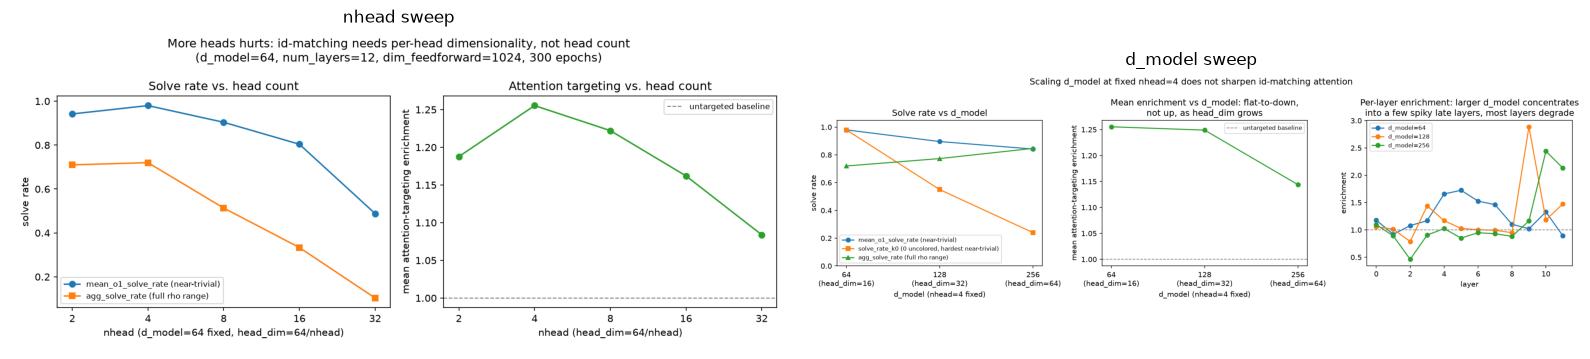

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(mpimg.imread("sudoku_nhead_sweep.png")); axes[0].axis("off"); axes[0].set_title("nhead sweep")
axes[1].imshow(mpimg.imread("sudoku_dmodel_sweep.png")); axes[1].axis("off"); axes[1].set_title("d_model sweep")
fig.tight_layout()
plt.show()

## Per-layer enrichment, both sweeps' nhead=4 point vs their off-optimum points

Not just the mean drops off-optimum -- the *shape* degrades too: the baseline has a smooth mid-layer peak, while both large-nhead and large-d_model configs collapse most layers toward/below the untargeted baseline (1.0) with one or two spiky outlier layers.

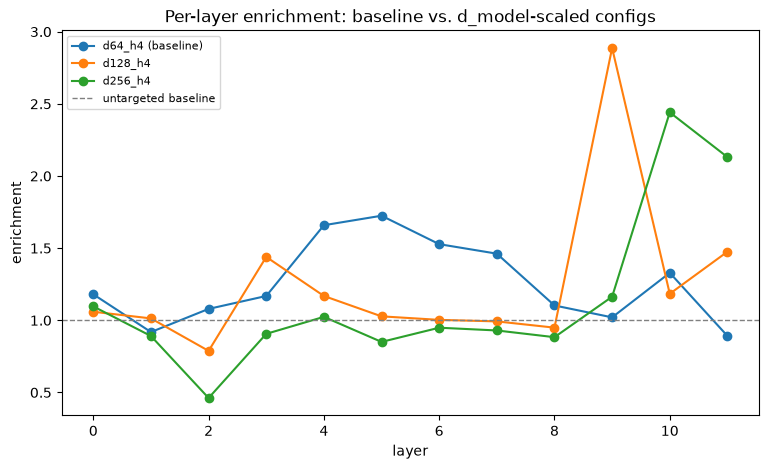

In [4]:
enrichment_by_layer = {
    "d64_h4 (baseline)": [1.1800297373646045, 0.9185781537940083, 1.079046243893263, 1.1686119031404325,
                           1.6590321965721389, 1.7247475752686032, 1.5277825124802675, 1.4618423412817418,
                           1.1028781277968325, 1.0204622359689943, 1.3291745478766779, 0.8919322991099964],
    "d64_h32 (worst nhead axis)": [1.0]*12,  # per-layer not retained for h32; mean=1.084 reported only
    "d128_h4": [1.059374654810914, 1.0131814556617738, 0.7881234869684568, 1.4392904444218646,
                1.1686854025522224, 1.027414553470763, 1.0030937068884516, 0.9924824991321539,
                0.9491681966939194, 2.8871699409278104, 1.183811858669829, 1.4754213668606349],
    "d256_h4": [1.0961432668580642, 0.8910833295998267, 0.46164131154660787, 0.9062403318646443,
                1.0239282341242737, 0.8503206856471254, 0.948710183507761, 0.9296407289064528,
                0.883063095650866, 1.163485401536499, 2.4412463046388693, 2.131150888757019],
}
fig, ax = plt.subplots(figsize=(9, 5))
for label, vals in enrichment_by_layer.items():
    if label.startswith("d64_h32"):
        continue  # placeholder, per-layer not retained
    ax.plot(range(12), vals, "o-", label=label)
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="untargeted baseline")
ax.set_xlabel("layer"); ax.set_ylabel("enrichment"); ax.legend(fontsize=8)
ax.set_title("Per-layer enrichment: baseline vs. d_model-scaled configs")
plt.show()

## Conclusion (negative result, both axes)

Scaling either head count (more, narrower heads) or head width (fewer-but-wider via larger `d_model` at fixed `nhead=4`) **fails to raise the content-addressing ceiling** found in the attention-distance analysis:

- `nhead=4, head_dim=16` is already a local optimum for `agg_solve_rate`, `mean_o1_solve_rate`, and `mean_enrichment` on the nhead axis -- more heads monotonically hurts all three (down to `agg_solve_rate=0.10` at `nhead=32`).
- Growing `d_model` at fixed `nhead=4` doesn't help either: `mean_enrichment` goes `1.255 -> 1.249 -> 1.144` (flat-to-down), and `mean_o1_solve_rate`/`solve_rate_k0` regress sharply (`0.980/0.98 -> 0.896/0.55 -> 0.842/0.24`) even though `agg_solve_rate` improves (`0.72 -> 0.77 -> 0.85`) and `final_val_nll` gets much worse (`1.2 -> 1.67 -> 2.41`).
- The `agg_solve_rate` up / `mean_o1_solve_rate` down split at larger `d_model` is itself unexplained -- could be overfitting to the harder/longer end of the training rho range at the cost of the trivial-copy case, or a genuine head_dim effect; not yet distinguished (would need e.g. extending `d_model=128/256` training epochs to rule out undertraining, which is not favored by the model-size scan's precedent since near-trivial cases historically converge *first*, not last).

**Net:** neither architecture axis alone fixes content-targeting. The recommended config remains `d_model=64, nhead=4, num_layers=12, dim_feedforward=1024`. Next steps worth considering (not yet run): a non-parameter-count architecture change aimed at content-addressing specifically (e.g. relative/rotary positional scheme, or an explicit copy/pointer mechanism), rather than further head-count/head-width sweeps.